In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
from skimage.color import rgb2lab, lab2rgb

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [ ]:
# Przygotowanie danych GTSRB

IMAGE_SIZE = 64
BATCH_SIZE = 64

# Transformacje dla oryginalnego kolorowego obrazu
transform_color = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor()
])

# Dane treningowe
train_dataset = datasets.GTSRB(
    root='./data',
    split='train',
    download=True,
    transform=transform_color
)

# Dane testowe
test_dataset = datasets.GTSRB(
    root='./data',
    split='test',
    download=True,
    transform=transform_color
)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)

print(f"Rozmiar zbioru treningowego: {len(train_dataset)} obrazów")
print(f"Rozmiar zbioru testowego: {len(test_dataset)} obrazów")

Rozmiar zbioru treningowego: 26640 obrazów
Rozmiar zbioru testowego: 12630 obrazów


In [ ]:
def get_lab_tensors(rgb_imgs, device):

    # Przejście na format numpy i zmiana przestrzeni barw na LAB
    imgs_np = rgb_imgs.permute(0, 2, 3, 1).cpu().numpy()
    lab_np = rgb2lab(imgs_np)

    # Zamiana z powrotem na tensory i normalizacja wartości
    lab_tensor = torch.tensor(lab_np, dtype=torch.float32).permute(0, 3, 1, 2)
    l_channel = lab_tensor[:, 0:1, :, :] / 100.0
    ab_channels = lab_tensor[:, 1:3, :, :] / 128.0

    return l_channel.to(device), ab_channels.to(device)

def lab_to_rgb_tensor(l_channel, ab_predicted):

    # Przywrócenie oryginalnej skali i połączenie jasności z kolorami
    l = l_channel * 100.0
    ab = ab_predicted * 128.0
    lab_tensor = torch.cat([l, ab], dim=1)

    # Transformacja danych do formatu obsługiwanego przez wyświetlanie obrazków
    lab_np = lab_tensor.permute(0, 2, 3, 1).cpu().numpy()
    rgb_imgs = [lab2rgb(img) for img in lab_np]

    return np.array(rgb_imgs)

In [ ]:
# 1. Definicja wspólnego Encodera
class Encoder(nn.Module):
    def __init__(self):
        super(Encoder, self).__init__()
        self.conv1 = nn.Conv2d(1, 64, 3, stride=2, padding=1)
        self.bn1 = nn.BatchNorm2d(64)
        self.conv2 = nn.Conv2d(64, 128, 3, stride=2, padding=1)
        self.bn2 = nn.BatchNorm2d(128)
        self.conv3 = nn.Conv2d(128, 256, 3, stride=2, padding=1)
        self.bn3 = nn.BatchNorm2d(256)
        self.conv4 = nn.Conv2d(256, 512, 3, stride=2, padding=1)
        self.bn4 = nn.BatchNorm2d(512)

        self.relu = nn.ReLU(inplace=True)

    def forward(self, x):
        # Przepuszczanie danych przez warstwy
        x = self.relu(self.bn1(self.conv1(x)))
        x = self.relu(self.bn2(self.conv2(x)))
        x = self.relu(self.bn3(self.conv3(x)))
        x = self.relu(self.bn4(self.conv4(x)))
        return x

# 2. Autoencoder powiększający przez Transposed Convolution
class AE_Transposed(nn.Module):
    def __init__(self):
        super(AE_Transposed, self).__init__()
        self.encoder = Encoder()
        self.deconv1 = nn.ConvTranspose2d(512, 256, 3, stride=2, padding=1, output_padding=1)
        self.bn1 = nn.BatchNorm2d(256)
        self.deconv2 = nn.ConvTranspose2d(256, 128, 3, stride=2, padding=1, output_padding=1)
        self.bn2 = nn.BatchNorm2d(128)
        self.deconv3 = nn.ConvTranspose2d(128, 64, 3, stride=2, padding=1, output_padding=1)
        self.bn3 = nn.BatchNorm2d(64)
        self.deconv4 = nn.ConvTranspose2d(64, 2, 3, stride=2, padding=1, output_padding=1)

        self.relu = nn.ReLU(inplace=True)
        self.tanh = nn.Tanh() # Ogranicza wartości kolorów do [-1,1]

    def forward(self, x):
        x = self.encoder(x)
        x = self.relu(self.bn1(self.deconv1(x)))
        x = self.relu(self.bn2(self.deconv2(x)))
        x = self.relu(self.bn3(self.deconv3(x)))
        out = self.tanh(self.deconv4(x))
        return out

# 3. Autoencoder powiększający przez Interpolację i Konwolucję
class AE_Interpolated(nn.Module):
    def __init__(self):
        super(AE_Interpolated, self).__init__()
        self.encoder = Encoder()
        self.conv1 = nn.Conv2d(512, 256, 3, padding=1)
        self.bn1 = nn.BatchNorm2d(256)
        self.conv2 = nn.Conv2d(256, 128, 3, padding=1)
        self.bn2 = nn.BatchNorm2d(128)
        self.conv3 = nn.Conv2d(128, 64, 3, padding=1)
        self.bn3 = nn.BatchNorm2d(64)
        self.conv4 = nn.Conv2d(64, 2, 3, padding=1)

        self.relu = nn.ReLU(inplace=True)
        self.tanh = nn.Tanh()

    def forward(self, x):
        x = self.encoder(x)
        x = F.interpolate(x, scale_factor=2, mode='bilinear', align_corners=False)
        x = self.relu(self.bn1(self.conv1(x)))
        x = F.interpolate(x, scale_factor=2, mode='bilinear', align_corners=False)
        x = self.relu(self.bn2(self.conv2(x)))
        x = F.interpolate(x, scale_factor=2, mode='bilinear', align_corners=False)
        x = self.relu(self.bn3(self.conv3(x)))
        x = F.interpolate(x, scale_factor=2, mode='bilinear', align_corners=False)
        x = self.tanh(self.conv4(x))

        return x


model_transposed = AE_Transposed().to(device)
model_interpolated = AE_Interpolated().to(device)

In [ ]:
# Pętla treningowa
def train_model(model, model_name, epochs):
    criterion = nn.L1Loss()
    optimizer = optim.Adam(model.parameters(), lr=0.001)
    history = []

    print(f"\n=== Trening w przestrzeni LAB: {model_name} ===")
    for epoch in range(epochs):
        model.train()
        running_loss = 0.0

        for color_imgs, _ in train_loader:

            l_channel, ab_channels = get_lab_tensors(color_imgs, device)

            optimizer.zero_grad()
            outputs = model(l_channel)
            loss = criterion(outputs, ab_channels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()

        epoch_loss = running_loss / len(train_loader)
        history.append(epoch_loss)
        print(f"Epoka [{epoch+1}/{epochs}] -> Loss: {epoch_loss:.5f}")

    return history

# Trening
epochs = 10
loss_transposed = train_model(model_transposed, "Transposed Convolution AE", epochs)
loss_interpolated = train_model(model_interpolated, "Interpolated + Convolution AE", epochs)


=== Trening w przestrzeni LAB: Transposed Convolution AE ===
Epoka [1/10] -> Loss: 0.05300
Epoka [2/10] -> Loss: 0.03856
Epoka [3/10] -> Loss: 0.03332
Epoka [4/10] -> Loss: 0.03095
Epoka [5/10] -> Loss: 0.02948
Epoka [6/10] -> Loss: 0.02797
Epoka [7/10] -> Loss: 0.02679
Epoka [8/10] -> Loss: 0.02568
Epoka [9/10] -> Loss: 0.02488
Epoka [10/10] -> Loss: 0.02403

=== Trening w przestrzeni LAB: Interpolated + Convolution AE ===
Epoka [1/10] -> Loss: 0.05285
Epoka [2/10] -> Loss: 0.04393
Epoka [3/10] -> Loss: 0.03910
Epoka [4/10] -> Loss: 0.03633
Epoka [5/10] -> Loss: 0.03333
Epoka [6/10] -> Loss: 0.03182
Epoka [7/10] -> Loss: 0.03093
Epoka [8/10] -> Loss: 0.02963
Epoka [9/10] -> Loss: 0.02851
Epoka [10/10] -> Loss: 0.02713


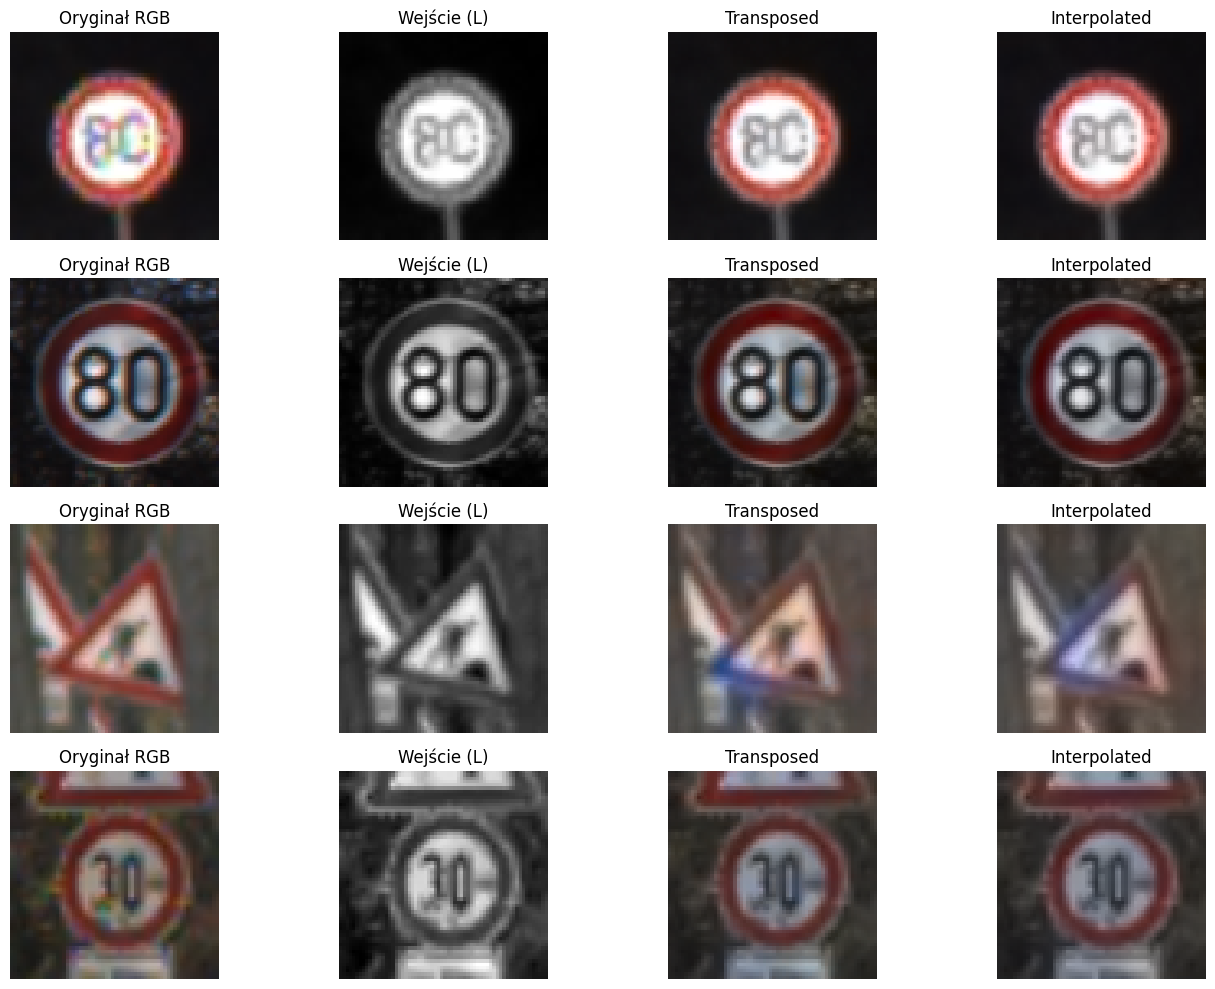

In [ ]:
# Ewaluacja
model_transposed.eval()
model_interpolated.eval()
samples_count = 4

indices = np.random.choice(len(test_dataset), samples_count, replace=False)
color_imgs = torch.stack([test_dataset[i][0] for i in indices])

org_imgs_np = color_imgs.permute(0, 2, 3, 1).numpy()

l_test, _ = get_lab_tensors(color_imgs, device)

# Predykcje kolorów
with torch.no_grad():
    pred_ab_trans = model_transposed(l_test)
    pred_ab_inter = model_interpolated(l_test)

rgb_trans = lab_to_rgb_tensor(l_test, pred_ab_trans)
rgb_inter = lab_to_rgb_tensor(l_test, pred_ab_inter)

# Rysowanie siatki
fig, axes = plt.subplots(samples_count, 4, figsize=(14, 10))
for i in range(samples_count):
    axes[i, 0].imshow(org_imgs_np[i])
    axes[i, 0].set_title("Oryginał RGB")
    axes[i, 1].imshow(l_test[i, 0].cpu(), cmap='gray')
    axes[i, 1].set_title("Wejście (L)")
    axes[i, 2].imshow(rgb_trans[i])
    axes[i, 2].set_title("Transposed")
    axes[i, 3].imshow(rgb_inter[i])
    axes[i, 3].set_title("Interpolated")
    for ax in axes[i]: ax.axis('off')

plt.tight_layout()
plt.show()

Skuteczność przestrzeni LAB:

Dzięki przeniesieniu problemu do przestrzeni LAB, struktura obrazu, ostre krawędzie, cyfry na znakach oraz detale tła pozostały w 100% nienaruszone i idealnie ostre.

Porównanie skuteczności obu modeli:

Na podstawie wyników nie jesteśmy w stanie dostrzec znaczących różnic, co oznacza, że oba modele radzą sobie równie dobrze z tym rodzajem danych.

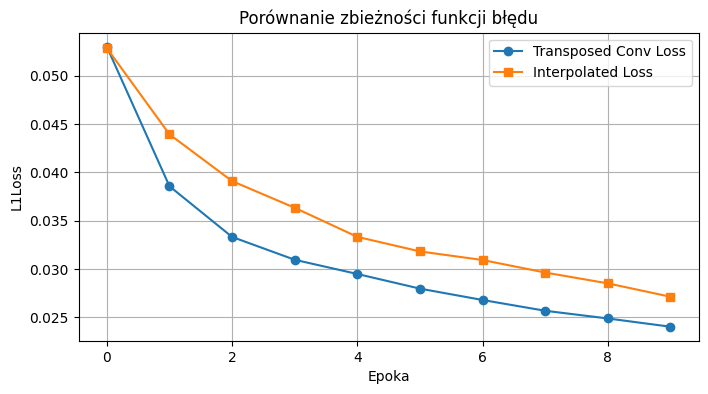

In [ ]:
# Porównanie zbieżności funkcji błędu
plt.figure(figsize=(8, 4))
plt.plot(loss_transposed, label='Transposed Conv Loss', marker='o')
plt.plot(loss_interpolated, label='Interpolated Loss', marker='s')
plt.xlabel('Epoka')
plt.ylabel('L1Loss')
plt.title('Porównanie zbieżności funkcji błędu')
plt.legend()
plt.grid(True)
plt.show()

Prawidłowa zbieżność obu modeli:

Obie krzywe wykazują stabilny spadek wartości błędu wraz z upływem kolejnych epok i zaczynają się wypłaszczać. Oznacza to, że proces uczenia zachodzi prawidłowo, a sieci skutecznie uczą się mapowania jasności na kolory.

Dynamika modelu Transposed:

 Model oparty na konwolucji transponowanej startuje z wyższego poziomu błędu początkowego, ale jego strata spada znacznie gwałtowniej. Pod kątem matematycznym, ten model lepiej dopasował się do danych.

Dynamika modelu Interpolated:

 Tempo uczenia modelu jest wolniejsze, a ostateczny błąd zatrzymuje się na minimalnie wyższym poziomie ok. 0.027.